# Week 6 — Warehouse Analytics

## Objective
Evaluate warehouse and branch performance using sales, inventory, stock movement, capacity, workforce, operating cost, and product-level stock health.

## Goals
- Measure warehouse throughput.
- Evaluate capacity and space-utilization indicators.
- Compare branch sales and operational efficiency.
- Analyse stock IN and OUT behavior.
- Identify warehouse bottlenecks.
- Benchmark branches using transparent KPIs.
- Connect Week 5 stagnation findings with warehouse performance.
- Evaluate product–warehouse alignment.

In [2]:
import pandas as pd
import numpy as np

warehouse_analysis = pd.read_csv(
    "analysis_ready_data/warehouse_analysis.csv"
)

product_branch_stock_health = pd.read_csv(
    "week5_outputs/product_branch_stock_health.csv"
)

stagnation_by_branch = pd.read_csv(
    "week5_outputs/stagnation_by_branch.csv"
)

In [3]:
branches = pd.read_csv(
    "processed_data/branches_clean.csv"
)

stock_ledger = pd.read_csv(
    "processed_data/stock_ledger_clean.csv"
)

stock_ledger["movement_date"] = pd.to_datetime(
    stock_ledger["movement_date"],
    errors="coerce"
)

In [4]:
print("Warehouse analysis rows:", len(warehouse_analysis))
print("Unique branches:", warehouse_analysis["branch_id"].nunique())

print("Branches master rows:", len(branches))
print("Stock ledger rows:", len(stock_ledger))

print(
    "Product-branch stock health rows:",
    len(product_branch_stock_health)
)

print(
    "Stagnation branch rows:",
    len(stagnation_by_branch)
)

Warehouse analysis rows: 6
Unique branches: 6
Branches master rows: 6
Stock ledger rows: 237230
Product-branch stock health rows: 180
Stagnation branch rows: 6


In [5]:
branch_movement = (
    stock_ledger
    .groupby(["branch_id", "movement_type"])
    .agg(
        total_quantity=("quantity", "sum"),
        movement_events=("movement_id", "count")
    )
    .reset_index()
)

In [6]:
branch_quantity = (
    branch_movement
    .pivot(
        index="branch_id",
        columns="movement_type",
        values="total_quantity"
    )
    .fillna(0)
    .reset_index()
)

branch_quantity.columns.name = None

branch_quantity = branch_quantity.rename(
    columns={
        "IN": "total_stock_in",
        "OUT": "total_stock_out",
        "ADJUSTMENT": "total_adjustment"
    }
)

In [7]:
branch_events = (
    branch_movement
    .pivot(
        index="branch_id",
        columns="movement_type",
        values="movement_events"
    )
    .fillna(0)
    .reset_index()
)

branch_events.columns.name = None

branch_events = branch_events.rename(
    columns={
        "IN": "stock_in_events",
        "OUT": "stock_out_events",
        "ADJUSTMENT": "adjustment_events"
    }
)

In [8]:
warehouse_throughput = branch_quantity.merge(
    branch_events,
    on="branch_id",
    how="left",
    validate="one_to_one"
)

In [9]:
warehouse_throughput["total_movement_volume"] = (
    warehouse_throughput["total_stock_in"]
    + warehouse_throughput["total_stock_out"]
    + warehouse_throughput["total_adjustment"]
)

warehouse_throughput["total_movement_events"] = (
    warehouse_throughput["stock_in_events"]
    + warehouse_throughput["stock_out_events"]
    + warehouse_throughput["adjustment_events"]
)

warehouse_throughput["outbound_share_percent"] = (
    warehouse_throughput["total_stock_out"]
    / warehouse_throughput["total_movement_volume"]
    * 100
)

In [10]:
warehouse_throughput = warehouse_throughput.merge(
    branches[
        [
            "branch_id",
            "branch_name",
            "warehouse_type",
            "warehouse_capacity_sqft"
        ]
    ],
    on="branch_id",
    how="left",
    validate="one_to_one"
)

In [11]:
warehouse_throughput[
    [
        "branch_id",
        "branch_name",
        "total_stock_in",
        "total_stock_out",
        "total_adjustment",
        "total_movement_volume",
        "total_movement_events",
        "outbound_share_percent"
    ]
].sort_values(
    "total_movement_volume",
    ascending=False
)

,branch_id,branch_name,total_stock_in,total_stock_out,total_adjustment,total_movement_volume,total_movement_events,outbound_share_percent
1,CHN001,Chennai South Hub,3461260,231544,11314,3704118,44029,6.250989
2,DEL001,Delhi Central,3453132,169332,10734,3633198,37967,4.660687
5,PUN001,Pune Distribution,3415584,165312,11278,3592174,37751,4.602004
3,HYD001,Hyderabad Logistics,3394339,153895,11650,3559884,36300,4.323034
4,KOL001,Kolkata East Depot,3328556,210007,11832,3550395,41272,5.915032
0,AHM001,Ahmedabad West Hub,3344924,194742,10182,3549848,39911,5.485925


### Initial Warehouse Throughput Findings

Warehouse throughput was evaluated using historical stock-ledger movements.

Chennai South Hub recorded the highest total stock movement volume and the highest number of movement events among the six branches.

Outbound stock represents only a small share of total movement volume across all branches, ranging from approximately 4% to 6%.

This pattern is consistent with the inventory-flow imbalance identified during Week 5, where historical stock inflows were substantially greater than stock outflows.

Raw throughput alone is not treated as a warehouse-performance score because differences in warehouse capacity, workforce, and operating role must also be considered.

In [12]:
warehouse_throughput = warehouse_throughput.merge(
    branches[
        [
            "branch_id",
            "total_employees"
        ]
    ],
    on="branch_id",
    how="left",
    validate="one_to_one"
)

In [13]:
warehouse_throughput["movement_volume_per_sqft"] = (
    warehouse_throughput["total_movement_volume"]
    / warehouse_throughput["warehouse_capacity_sqft"]
)

warehouse_throughput["movement_events_per_employee"] = (
    warehouse_throughput["total_movement_events"]
    / warehouse_throughput["total_employees"]
)

warehouse_throughput["stock_out_per_employee"] = (
    warehouse_throughput["total_stock_out"]
    / warehouse_throughput["total_employees"]
)

In [14]:
warehouse_throughput[
    [
        "branch_id",
        "branch_name",
        "warehouse_capacity_sqft",
        "total_employees",
        "total_movement_volume",
        "movement_volume_per_sqft",
        "movement_events_per_employee",
        "stock_out_per_employee"
    ]
].sort_values(
    "movement_volume_per_sqft",
    ascending=False
)

,branch_id,branch_name,warehouse_capacity_sqft,total_employees,total_movement_volume,movement_volume_per_sqft,movement_events_per_employee,stock_out_per_employee
4,KOL001,Kolkata East Depot,29880,49,3550395,118.821787,842.285714,4285.857143
0,AHM001,Ahmedabad West Hub,34120,63,3549848,104.040094,633.507937,3091.142857
3,HYD001,Hyderabad Logistics,36210,57,3559884,98.312179,636.842105,2699.912281
5,PUN001,Pune Distribution,38750,74,3592174,92.701265,510.148649,2233.945946
1,CHN001,Chennai South Hub,41890,81,3704118,88.424875,543.567901,2858.567901
2,DEL001,Delhi Central,45230,92,3633198,80.327172,412.684783,1840.565217


In [15]:
warehouse_benchmark = warehouse_analysis.merge(
    warehouse_throughput[
        [
            "branch_id",
            "total_movement_volume",
            "total_movement_events",
            "outbound_share_percent",
            "movement_volume_per_sqft",
            "movement_events_per_employee",
            "stock_out_per_employee"
        ]
    ],
    on="branch_id",
    how="left",
    validate="one_to_one"
)

In [16]:
warehouse_benchmark = warehouse_benchmark.merge(
    stagnation_by_branch[
        [
            "branch_id",
            "stagnation_cases",
            "affected_products",
            "inventory_value_at_risk"
        ]
    ],
    on="branch_id",
    how="left",
    validate="one_to_one"
)

In [17]:
print(
    "Missing stagnation cases:",
    warehouse_benchmark["stagnation_cases"].isna().sum()
)

print(
    "Warehouse benchmark rows:",
    len(warehouse_benchmark)
)

Missing stagnation cases: 0
Warehouse benchmark rows: 6


In [18]:
warehouse_benchmark["sales_per_sqft"] = (
    warehouse_benchmark["total_sales_value"]
    / warehouse_benchmark["warehouse_capacity_sqft"]
)

warehouse_benchmark["units_sold_per_employee"] = (
    warehouse_benchmark["total_units_sold"]
    / warehouse_benchmark["total_employees"]
)

warehouse_benchmark["stagnation_rate_percent"] = (
    warehouse_benchmark["stagnation_cases"]
    / warehouse_benchmark["product_count"]
    * 100
)

In [19]:
warehouse_benchmark[
    [
        "branch_id",
        "branch_name",
        "warehouse_type",
        "warehouse_capacity_sqft",
        "total_employees",
        "total_sales_value",
        "sales_per_sqft",
        "movement_volume_per_sqft",
        "movement_events_per_employee",
        "units_sold_per_employee",
        "operating_cost_ratio",
        "stagnation_cases",
        "stagnation_rate_percent"
    ]
].sort_values(
    "sales_per_sqft",
    ascending=False
)

,branch_id,branch_name,warehouse_type,warehouse_capacity_sqft,total_employees,total_sales_value,sales_per_sqft,movement_volume_per_sqft,movement_events_per_employee,units_sold_per_employee,operating_cost_ratio,stagnation_cases,stagnation_rate_percent
4,KOL001,Kolkata East Depot,Branch,29880,49,4787656160,160229.456493,118.821787,842.285714,5226.428571,0.602120,4,13.333333
5,AHM001,Ahmedabad West Hub,Service Hub,34120,63,4407886140,129187.753224,104.040094,633.507937,3751.539683,0.621709,1,3.333333
2,CHN001,Chennai South Hub,Regional,41890,81,5192125100,123946.648365,88.424875,543.567901,3462.296296,0.599635,1,3.333333
1,PUN001,Pune Distribution,Regional,38750,74,3741098180,96544.469161,92.701265,510.148649,2726.337838,0.604677,3,10.000000
3,HYD001,Hyderabad Logistics,Branch,36210,57,3452672510,95351.353494,98.312179,636.842105,3318.649123,0.608228,3,10.000000
0,DEL001,Delhi Central,Central,45230,92,3865954470,85473.236126,80.327172,412.684783,2225.369565,0.609182,3,10.000000


In [20]:
sales_sqft_q25 = warehouse_benchmark["sales_per_sqft"].quantile(0.25)
throughput_q25 = warehouse_benchmark["movement_volume_per_sqft"].quantile(0.25)
cost_q75 = warehouse_benchmark["operating_cost_ratio"].quantile(0.75)
stagnation_q75 = warehouse_benchmark["stagnation_rate_percent"].quantile(0.75)

In [21]:
warehouse_benchmark["bottleneck_count"] = (
    (warehouse_benchmark["sales_per_sqft"] <= sales_sqft_q25).astype(int)
    + (warehouse_benchmark["movement_volume_per_sqft"] <= throughput_q25).astype(int)
    + (warehouse_benchmark["operating_cost_ratio"] >= cost_q75).astype(int)
    + (warehouse_benchmark["stagnation_rate_percent"] >= stagnation_q75).astype(int)
)

In [22]:
warehouse_benchmark["bottleneck_status"] = np.select(
    [
        warehouse_benchmark["bottleneck_count"] >= 3,
        warehouse_benchmark["bottleneck_count"] == 2,
        warehouse_benchmark["bottleneck_count"] == 1
    ],
    [
        "High Bottleneck Risk",
        "Moderate Bottleneck Risk",
        "Watch"
    ],
    default="No Major Bottleneck"
)

In [23]:
warehouse_benchmark[
    [
        "branch_id",
        "branch_name",
        "bottleneck_count",
        "bottleneck_status"
    ]
].sort_values(
    "bottleneck_count",
    ascending=False
)

,branch_id,branch_name,bottleneck_count,bottleneck_status
0,DEL001,Delhi Central,4,High Bottleneck Risk
3,HYD001,Hyderabad Logistics,2,Moderate Bottleneck Risk
1,PUN001,Pune Distribution,1,Watch
2,CHN001,Chennai South Hub,1,Watch
4,KOL001,Kolkata East Depot,1,Watch
5,AHM001,Ahmedabad West Hub,1,Watch


### Initial Warehouse Bottleneck Screening

Warehouse bottlenecks were screened using four relative indicators:

- Low sales per square foot
- Low movement volume per square foot
- High operating-cost ratio
- High potential-stagnation rate

Delhi Central triggered all four relative bottleneck indicators and was classified as High Bottleneck Risk.

Hyderabad Logistics triggered two indicators and was classified as Moderate Bottleneck Risk.

The remaining branches triggered one indicator each and were classified as Watch.

These classifications are relative to the six warehouses in this dataset and should be interpreted as benchmarking signals rather than absolute operational failure.

In [24]:
warehouse_benchmark["low_sales_density_flag"] = (
    warehouse_benchmark["sales_per_sqft"] <= sales_sqft_q25
)

warehouse_benchmark["low_throughput_density_flag"] = (
    warehouse_benchmark["movement_volume_per_sqft"] <= throughput_q25
)

warehouse_benchmark["high_cost_flag"] = (
    warehouse_benchmark["operating_cost_ratio"] >= cost_q75
)

warehouse_benchmark["high_stagnation_flag"] = (
    warehouse_benchmark["stagnation_rate_percent"] >= stagnation_q75
)


In [25]:
def get_bottleneck_reasons(row):
    reasons = []

    if row["low_sales_density_flag"]:
        reasons.append("Low Sales Density")

    if row["low_throughput_density_flag"]:
        reasons.append("Low Throughput Density")

    if row["high_cost_flag"]:
        reasons.append("High Operating Cost")

    if row["high_stagnation_flag"]:
        reasons.append("High Stagnation")

    if not reasons:
        return "None"

    return ", ".join(reasons)

warehouse_benchmark["bottleneck_reasons"] = (
    warehouse_benchmark.apply(
        get_bottleneck_reasons,
        axis=1
    )
)

In [26]:
warehouse_benchmark[
    [
        "branch_id",
        "branch_name",
        "bottleneck_count",
        "bottleneck_status",
        "bottleneck_reasons"
    ]
].sort_values(
    "bottleneck_count",
    ascending=False
)

,branch_id,branch_name,bottleneck_count,bottleneck_status,bottleneck_reasons
0,DEL001,Delhi Central,4,High Bottleneck Risk,"Low Sales Density, Low Throughput Density, Hig..."
3,HYD001,Hyderabad Logistics,2,Moderate Bottleneck Risk,"Low Sales Density, High Stagnation"
1,PUN001,Pune Distribution,1,Watch,High Stagnation
2,CHN001,Chennai South Hub,1,Watch,Low Throughput Density
4,KOL001,Kolkata East Depot,1,Watch,High Stagnation
5,AHM001,Ahmedabad West Hub,1,Watch,High Operating Cost


### Warehouse Bottleneck Interpretation

Warehouse bottlenecks were evaluated using relative operational indicators rather than raw activity alone.

Delhi Central triggered all four bottleneck signals: low sales density, low throughput density, high operating cost, and high product stagnation. It therefore represents the strongest relative bottleneck candidate among the six warehouses.

Hyderabad Logistics showed both low sales density and high stagnation, resulting in moderate bottleneck risk.

Pune Distribution and Kolkata East Depot were primarily affected by higher stagnation, while Ahmedabad West Hub was mainly affected by its relatively high operating-cost ratio.

Chennai South Hub illustrates the importance of normalization. Although it recorded the highest total stock movement volume, its movement volume relative to warehouse capacity was comparatively low.

These classifications represent relative benchmarking within the six-warehouse network and do not imply absolute operational failure.

In [27]:
warehouse_benchmark["sales_density_rank"] = (
    warehouse_benchmark["sales_per_sqft"]
    .rank(ascending=False, method="dense")
    .astype(int)
)

warehouse_benchmark["throughput_density_rank"] = (
    warehouse_benchmark["movement_volume_per_sqft"]
    .rank(ascending=False, method="dense")
    .astype(int)
)

warehouse_benchmark["workforce_productivity_rank"] = (
    warehouse_benchmark["units_sold_per_employee"]
    .rank(ascending=False, method="dense")
    .astype(int)
)

warehouse_benchmark["cost_efficiency_rank"] = (
    warehouse_benchmark["operating_cost_ratio"]
    .rank(ascending=True, method="dense")
    .astype(int)
)

warehouse_benchmark["stock_health_rank"] = (
    warehouse_benchmark["stagnation_rate_percent"]
    .rank(ascending=True, method="dense")
    .astype(int)
)

In [28]:
warehouse_benchmark[
    [
        "branch_id",
        "branch_name",
        "sales_density_rank",
        "throughput_density_rank",
        "workforce_productivity_rank",
        "cost_efficiency_rank",
        "stock_health_rank",
        "bottleneck_status"
    ]
].sort_values(
    "sales_density_rank"
)

,branch_id,branch_name,sales_density_rank,throughput_density_rank,workforce_productivity_rank,cost_efficiency_rank,stock_health_rank,bottleneck_status
4,KOL001,Kolkata East Depot,1,1,1,2,3,Watch
5,AHM001,Ahmedabad West Hub,2,2,2,6,1,Watch
2,CHN001,Chennai South Hub,3,5,3,1,1,Watch
1,PUN001,Pune Distribution,4,4,5,3,2,Watch
3,HYD001,Hyderabad Logistics,5,3,4,4,2,Moderate Bottleneck Risk
0,DEL001,Delhi Central,6,6,6,5,2,High Bottleneck Risk


In [29]:
product_performance = pd.read_csv(
    "week4_outputs/product_performance.csv"
)

product_warehouse_alignment = product_branch_stock_health.merge(
    product_performance[
        [
            "product_id",
            "abc_class",
            "movement_class",
            "priority_group"
        ]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

In [30]:
product_warehouse_alignment["alignment_status"] = np.select(
    [
        (
            product_warehouse_alignment["abc_class"] == "A"
        )
        & (
            product_warehouse_alignment["stock_health_flag"]
            == "Potential Stagnation"
        ),

        (
            product_warehouse_alignment["abc_class"] == "A"
        )
        & (
            product_warehouse_alignment["stock_health_flag"]
            == "Healthy Movement"
        ),

        (
            product_warehouse_alignment["abc_class"] == "C"
        )
        & (
            product_warehouse_alignment["stock_health_flag"]
            == "Potential Stagnation"
        )
    ],
    [
        "Strategic Misalignment",
        "Strong Alignment",
        "Low-Priority Stagnation"
    ],
    default="Standard Alignment"
)

In [31]:
product_warehouse_alignment[
    "alignment_status"
].value_counts()

alignment_status
Standard Alignment         162
Strong Alignment             8
Strategic Misalignment       6
Low-Priority Stagnation      4
Name: count, dtype: int64

### Product–Warehouse Alignment

Product importance from Week 4 was combined with product-branch stock health from Week 5 to evaluate warehouse alignment.

Across the 180 product-branch combinations:

- 162 showed Standard Alignment.
- 8 showed Strong Alignment.
- 6 were classified as Strategic Misalignment.
- 4 showed Low-Priority Stagnation.

Strategic Misalignment identifies Class A products that show potential stagnation at a specific warehouse. Because these products are major revenue contributors, their warehouse placement and local movement deserve further investigation.

Low-Priority Stagnation represents Class C products with potential stagnation, which may become candidates for inventory redistribution or holding review.

These classifications are relative operational indicators and do not by themselves prove that inventory should be transferred or reduced.

In [32]:
strategic_misalignment = product_warehouse_alignment[
    product_warehouse_alignment["alignment_status"]
    == "Strategic Misalignment"
].copy()

In [33]:
strategic_misalignment[
    [
        "branch_id",
        "branch_name",
        "product_id",
        "product_name",
        "abc_class",
        "days_since_last_movement",
        "turnover_class",
        "stock_health_flag"
    ]
].sort_values(
    ["branch_id", "days_since_last_movement"],
    ascending=[True, False]
)

,branch_id,branch_name,product_id,product_name,abc_class,days_since_last_movement,turnover_class,stock_health_flag
23,AHM001,Ahmedabad West Hub,P004,Track Chain TC-45,A,16,Low Turnover,Potential Stagnation
78,DEL001,Delhi Central,P014,Transmission Assembly TA-800,A,16,Low Turnover,Potential Stagnation
81,HYD001,Hyderabad Logistics,P014,Transmission Assembly TA-800,A,13,Low Turnover,Potential Stagnation
82,KOL001,Kolkata East Depot,P014,Transmission Assembly TA-800,A,18,Low Turnover,Potential Stagnation
22,KOL001,Kolkata East Depot,P004,Track Chain TC-45,A,14,Low Turnover,Potential Stagnation
79,PUN001,Pune Distribution,P014,Transmission Assembly TA-800,A,15,Low Turnover,Potential Stagnation


In [34]:
misalignment_by_branch = (
    strategic_misalignment
    .groupby(["branch_id", "branch_name"])
    .agg(
        strategic_misalignment_cases=("product_id", "count"),
        affected_strategic_products=("product_id", "nunique")
    )
    .reset_index()
    .sort_values(
        "strategic_misalignment_cases",
        ascending=False
    )
)

misalignment_by_branch

,branch_id,branch_name,strategic_misalignment_cases,affected_strategic_products
3,KOL001,Kolkata East Depot,2,2
0,AHM001,Ahmedabad West Hub,1,1
1,DEL001,Delhi Central,1,1
2,HYD001,Hyderabad Logistics,1,1
4,PUN001,Pune Distribution,1,1


In [35]:
misalignment_by_product = (
    strategic_misalignment
    .groupby(["product_id", "product_name"])
    .agg(
        affected_branches=("branch_id", "nunique"),
        misalignment_cases=("branch_id", "count")
    )
    .reset_index()
    .sort_values(
        ["affected_branches", "misalignment_cases"],
        ascending=False
    )
)

misalignment_by_product

,product_id,product_name,affected_branches,misalignment_cases
1,P014,Transmission Assembly TA-800,4,4
0,P004,Track Chain TC-45,2,2


### Strategic Product–Warehouse Misalignment

Strategic misalignment was identified when a Class A product showed potential stagnation at a specific warehouse.

Across the six warehouses:

- Kolkata East Depot had 2 strategic misalignment cases.
- Ahmedabad West Hub had 1 case.
- Delhi Central had 1 case.
- Hyderabad Logistics had 1 case.
- Pune Distribution had 1 case.
- Chennai South Hub had no strategic misalignment cases.

Kolkata East Depot therefore shows the strongest concentration of strategically important products with weak local movement.

This does not automatically imply that inventory should be transferred. It indicates that product placement, local demand, and stock allocation should be reviewed more closely for these cases.

In [36]:
final_warehouse_view = warehouse_benchmark[
    [
        "branch_id",
        "branch_name",
        "warehouse_type",
        "total_sales_value",
        "sales_per_sqft",
        "movement_volume_per_sqft",
        "movement_events_per_employee",
        "units_sold_per_employee",
        "operating_cost_ratio",
        "stagnation_rate_percent",
        "bottleneck_count",
        "bottleneck_status",
        "bottleneck_reasons"
    ]
].copy()

In [37]:
final_warehouse_view = final_warehouse_view.merge(
    misalignment_by_branch[
        [
            "branch_id",
            "strategic_misalignment_cases"
        ]
    ],
    on="branch_id",
    how="left",
    validate="one_to_one"
)

final_warehouse_view["strategic_misalignment_cases"] = (
    final_warehouse_view["strategic_misalignment_cases"]
    .fillna(0)
    .astype(int)
)

In [38]:
final_warehouse_view.sort_values(
    ["bottleneck_count", "strategic_misalignment_cases"],
    ascending=[False, False]
)

,branch_id,branch_name,warehouse_type,total_sales_value,sales_per_sqft,movement_volume_per_sqft,movement_events_per_employee,units_sold_per_employee,operating_cost_ratio,stagnation_rate_percent,bottleneck_count,bottleneck_status,bottleneck_reasons,strategic_misalignment_cases
0,DEL001,Delhi Central,Central,3865954470,85473.236126,80.327172,412.684783,2225.369565,0.609182,10.000000,4,High Bottleneck Risk,"Low Sales Density, Low Throughput Density, Hig...",1
3,HYD001,Hyderabad Logistics,Branch,3452672510,95351.353494,98.312179,636.842105,3318.649123,0.608228,10.000000,2,Moderate Bottleneck Risk,"Low Sales Density, High Stagnation",1
4,KOL001,Kolkata East Depot,Branch,4787656160,160229.456493,118.821787,842.285714,5226.428571,0.602120,13.333333,1,Watch,High Stagnation,2
1,PUN001,Pune Distribution,Regional,3741098180,96544.469161,92.701265,510.148649,2726.337838,0.604677,10.000000,1,Watch,High Stagnation,1
5,AHM001,Ahmedabad West Hub,Service Hub,4407886140,129187.753224,104.040094,633.507937,3751.539683,0.621709,3.333333,1,Watch,High Operating Cost,1
2,CHN001,Chennai South Hub,Regional,5192125100,123946.648365,88.424875,543.567901,3462.296296,0.599635,3.333333,1,Watch,Low Throughput Density,0


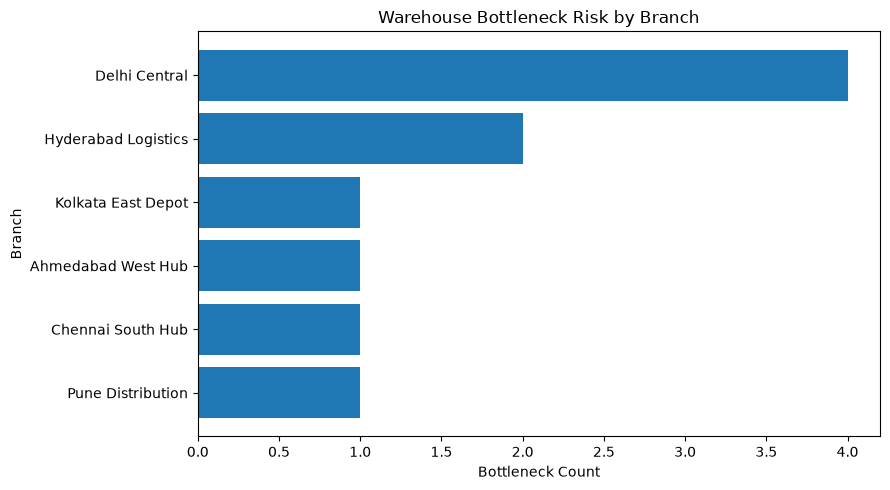

In [39]:
import matplotlib.pyplot as plt

bottleneck_plot = final_warehouse_view.sort_values(
    "bottleneck_count",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    bottleneck_plot["branch_name"],
    bottleneck_plot["bottleneck_count"]
)

plt.xlabel("Bottleneck Count")
plt.ylabel("Branch")
plt.title("Warehouse Bottleneck Risk by Branch")

plt.tight_layout()
plt.show()

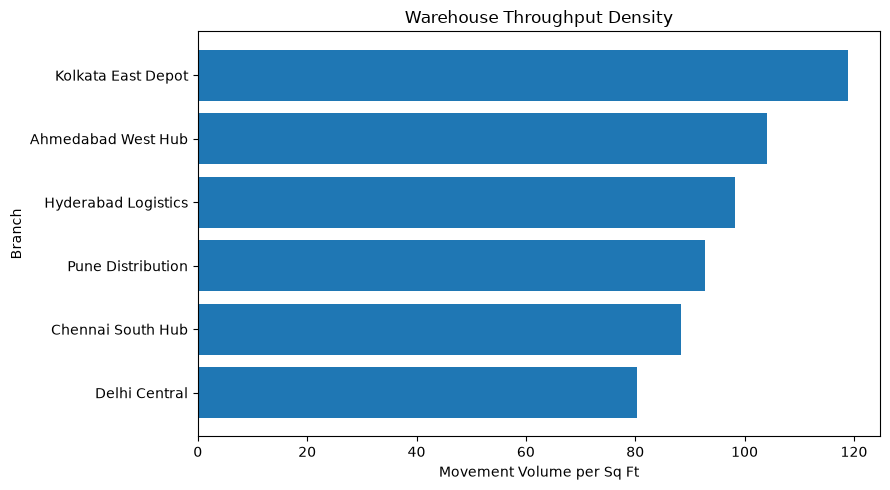

In [40]:
throughput_plot = final_warehouse_view.sort_values(
    "movement_volume_per_sqft",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    throughput_plot["branch_name"],
    throughput_plot["movement_volume_per_sqft"]
)

plt.xlabel("Movement Volume per Sq Ft")
plt.ylabel("Branch")
plt.title("Warehouse Throughput Density")

plt.tight_layout()
plt.show()

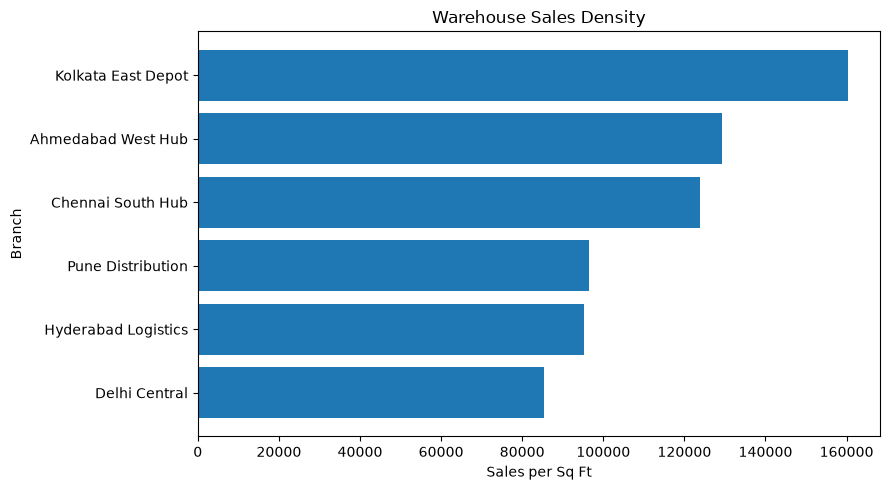

In [41]:
sales_density_plot = final_warehouse_view.sort_values(
    "sales_per_sqft",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    sales_density_plot["branch_name"],
    sales_density_plot["sales_per_sqft"]
)

plt.xlabel("Sales per Sq Ft")
plt.ylabel("Branch")
plt.title("Warehouse Sales Density")

plt.tight_layout()
plt.show()

In [42]:
print("Final warehouse rows:", len(final_warehouse_view))
print(
    "Unique branches:",
    final_warehouse_view["branch_id"].nunique()
)

print(
    "Product-warehouse alignment rows:",
    len(product_warehouse_alignment)
)

print(
    "Unique product-branch combinations:",
    product_warehouse_alignment[
        ["product_id", "branch_id"]
    ].drop_duplicates().shape[0]
)

print(
    "Missing bottleneck status:",
    final_warehouse_view["bottleneck_status"].isna().sum()
)

print(
    "Missing alignment status:",
    product_warehouse_alignment["alignment_status"].isna().sum()
)

Final warehouse rows: 6
Unique branches: 6
Product-warehouse alignment rows: 180
Unique product-branch combinations: 180
Missing bottleneck status: 0
Missing alignment status: 0


In [43]:
import os

os.makedirs("week6_outputs", exist_ok=True)

warehouse_throughput.to_csv(
    "week6_outputs/warehouse_throughput.csv",
    index=False
)

warehouse_benchmark.to_csv(
    "week6_outputs/warehouse_benchmark.csv",
    index=False
)

product_warehouse_alignment.to_csv(
    "week6_outputs/product_warehouse_alignment.csv",
    index=False
)

misalignment_by_branch.to_csv(
    "week6_outputs/misalignment_by_branch.csv",
    index=False
)

final_warehouse_view.to_csv(
    "week6_outputs/final_warehouse_view.csv",
    index=False
)

print("Week 6 outputs exported successfully.")

Week 6 outputs exported successfully.


In [44]:
for file in os.listdir("week6_outputs"):
    print(file)

final_warehouse_view.csv
misalignment_by_branch.csv
product_warehouse_alignment.csv
warehouse_benchmark.csv
warehouse_throughput.csv
